# Proyecto final · Fase 4 · Semana 3
## Visualización y comunicación de resultados

**Proyecto:** Fallas recurrentes de transmisión en la red de un operador móvil (NOC, octubre de 2026)
**Curso:** MCDI500 · Programación para la Ciencia de Datos · Magíster en Ciencia de Datos e IA, UNAB
**Integrante:** Edgar Arcia Velásquez (Grupo 6) · **Docente:** Dr. Omar Salinas Silva

---

Este notebook cierra el proyecto. **No vuelve a limpiar ni a transformar**: lee las tablas que dejó la
Fase 3 en `data/processed`, comprueba que son las correctas y responde con figuras los objetivos
específicos de la Fase 1.

| Fase | Notebook | Qué entrega a la siguiente |
|---|---|---|
| F1 | `F1/F1_Definicion.ipynb` | Problema, objetivos, entorno y calidad del conjunto |
| F2 | `F2/F2_Preprocesamiento.ipynb` | Limpieza justificada y tabla de recurrencia por sitio |
| F3 | `F3/F3_Nucleo_Eficiencia_POO.ipynb` | Pipeline en módulos y clases, mismo resultado que F2, mediciones y pruebas |
| **F4** | **este notebook** | Tres figuras, hallazgos, lista de escalamiento y evidencia para el informe y el video |

**Cómo usarlo.** Ejecute antes F1, F2 y F3, en ese orden. Si faltan las tablas de la Fase 3, el
notebook se detiene con un mensaje que dice qué ejecutar: no genera datos de reemplazo.

**El principio que ordena la fase.** Cada figura responde un objetivo de la Fase 1, y su título dice
el hallazgo, no el tipo de gráfico.

| Objetivo específico (Fase 1) | Figura que lo responde |
|---|---|
| 1. Fallas y minutos fuera de servicio por sitio, sin contar dos veces los traslapes | Figura 1 |
| 2. Sitios recurrentes y qué parte del tiempo fuera de servicio concentran | Figura 1 |
| 3. Tipo de enlace y proveedor que originan más fallas y más minutos | Figura 2 |
| 4. Lista de prioridad para escalar | Figura 3 y tabla de prioridad |

## 1. Entorno y ubicación del proyecto

La misma verificación de las fases anteriores, con una línea más: `sys.prefix != sys.base_prefix`
solo es verdadero si el kernel corre dentro del entorno virtual del proyecto.

In [1]:
import sys
import json
import platform
import subprocess
import unittest
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)
pd.set_option("display.width", 160)

print(f"Python {platform.python_version()}")
print("Entorno virtual activo:", sys.prefix != sys.base_prefix)
for lib in (np, pd, matplotlib):
    print(f"  {lib.__name__:<11} {lib.__version__}")
assert sys.prefix != sys.base_prefix, "El kernel no es el del proyecto: Kernel > Change Kernel > Python (mcdi500)"


def localizar_raiz(inicio=None):
    '''Primera carpeta hacia arriba que contiene requirements.txt (la raíz del proyecto).'''
    actual = Path(inicio or Path.cwd()).resolve()
    for carpeta in [actual, *actual.parents]:
        if (carpeta / "requirements.txt").is_file():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del proyecto (requirements.txt)")


RAIZ = localizar_raiz()
DIR_PROC, DIR_DOCS = RAIZ / "data" / "processed", RAIZ / "docs"
DIR_FIG = RAIZ / "F4" / "figuras"

sys.path.insert(0, str(RAIZ))
from src import comunicacion as com, limpieza
from src.medicion import comparar


def git(*argumentos):
    '''Ejecuta un comando de git en la raíz del proyecto y devuelve su salida.'''
    return subprocess.run(["git", *argumentos], cwd=RAIZ, capture_output=True, text=True).stdout.strip()


print("Raíz del proyecto:", RAIZ.name, "· rama:", git("rev-parse", "--abbrev-ref", "HEAD"),
      "· commit:", git("rev-parse", "--short", "HEAD"))

Python 3.14.6
Entorno virtual activo: True
  numpy       2.5.4
  pandas      3.1.1
  matplotlib  3.11.2
Raíz del proyecto: mcdi500-grupo6 · rama: f4-visualizacion · commit: da3c729


### Estilo de las figuras

Se define una sola vez, para que las tres figuras se lean como un conjunto. El color tiene función: el
granate marca lo que la figura quiere que se mire, el azul es la comparación y el gris, el contexto.
Todas las figuras usan solo Matplotlib, que ya está en `requirements.txt`; no se agrega otra librería.

In [2]:
GRANATE, AZUL, GRIS, HIELO, TINTA = "#AC212E", "#06304A", "#8A94A0", "#D7E3EE", "#0A1526"

plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (8, 4.4), "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": TINTA, "axes.edgecolor": GRIS,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
FUENTE = "Fuente: elaboración propia con el registro de incidencias del NOC, octubre de 2026 (sitios codificados)."


def nota_fuente(figura, texto=FUENTE):
    '''Escribe la fuente bajo la figura, sin tapar la etiqueta del eje x.'''
    figura.text(0.01, -0.02, texto, fontsize=8, color=GRIS, ha="left", va="top")


def pct(proporcion, decimales=0):
    '''Porcentaje con coma decimal, como se escribe en el informe.'''
    return f"{proporcion * 100:.{decimales}f} %".replace(".", ",")


def miles(numero):
    '''Entero con punto como separador de miles.'''
    return f"{int(round(numero)):,}".replace(",", ".")

---
## 2. Lo que entregó la Fase 3

### 2.1 Carga

`com.cargar_artefactos` lee los cuatro archivos y convierte las fechas, que el CSV guarda como texto.
Si falta alguno, se detiene con `FileNotFoundError` y dice qué notebook ejecutar.

In [3]:
artefactos = com.cargar_artefactos(DIR_PROC)
for nombre, tabla in artefactos.items():
    print(f"{nombre:<12} {tabla.shape[0]:>6} filas × {tabla.shape[1]:>2} columnas   ({com.ARTEFACTOS[nombre]})")

limpio, recurrencia = artefactos["limpio"], artefactos["recurrencia"]

limpio        21542 filas × 34 columnas   (incidencias_limpio.csv)
recurrencia     559 filas × 10 columnas   (recurrencia_tx_por_sitio.csv)
diccionario      92 filas ×  5 columnas   (diccionario_f3.csv)
parametros       15 filas ×  4 columnas   (parametros_f3.csv)


### 2.2 El contrato de la tabla por sitio

Antes de graficar se comprueba que la tabla cumple las reglas que debe cumplir si la Fase 2 calculó
bien. La más importante es la de los traslapes: los minutos reales (con los intervalos fusionados)
nunca pueden superar a los minutos sumados.

In [4]:
contrato = com.verificar_recurrencia(recurrencia)
for control, cumple in contrato.items():
    print(f"[{'OK' if cumple else 'FALLA'}] {control}")
assert all(contrato.values()), "La tabla de recurrencia no cumple su contrato"

[OK] Un sitio por fila
[OK] Cada sitio tiene al menos una falla
[OK] Fallas P3E no superan las fallas
[OK] Minutos reales no superan los sumados
[OK] Horas = minutos reales / 60
[OK] Sin vacíos en las columnas que se grafican


### 2.3 La verificación que más rinde: recalcular desde la tabla limpia

Comprobar la tabla con el mismo archivo que la contiene sería circular. Aquí se vuelve a calcular la
recurrencia desde `incidencias_limpio.csv` con la función de la Fase 3 y se compara con
`pd.testing.assert_frame_equal` contra la tabla que guardó la Fase 2. Si coinciden, las figuras de esta
fase descansan sobre exactamente el mismo resultado que se documentó antes.

In [5]:
recalculada = limpieza.tabla_recurrencia(limpio)
pd.testing.assert_frame_equal(recalculada, recurrencia, check_dtype=False)
recalculo_identico = True                     # si no coincidiera, la línea anterior detiene el notebook
print(f"Recalculada desde la tabla limpia: {len(recalculada)} sitios, idéntica a recurrencia_tx_por_sitio.csv")

Recalculada desde la tabla limpia: 559 sitios, idéntica a recurrencia_tx_por_sitio.csv


### 2.4 Por qué se grafica con la tabla interpretable y no con la de modelo

La Fase 2 dejó dos versiones: `incidencias_limpio` (categorías y unidades originales) e
`incidencias_modelo` (columnas 0/1 y variables escaladas, sin vacíos). La segunda sirve para un modelo,
pero un gráfico hecho con ella es ilegible: la duración está en desviaciones estándar y el tipo de
enlace está repartido en columnas de ceros y unos. Por eso esta fase usa la tabla limpia y la de
recurrencia, que están en horas y con los nombres de cada categoría.

In [6]:
modelo = pd.read_csv(DIR_PROC / "incidencias_modelo.csv", nrows=3)
binarias = [c for c in modelo.columns if c.startswith(("tipo_enlace_", "proveedor_"))]
print("Conjunto de modelo:", modelo.shape[1], "columnas, por ejemplo:")
print(modelo[["duracion_log_esc"] + binarias[:3]].to_string(index=False))
print("\nTabla interpretable (la que se grafica):")
print(recurrencia[["sitio", "fallas", "horas_fuera", "enlace_principal", "proveedor_tx"]].head(3).to_string(index=False))

Conjunto de modelo: 48 columnas, por ejemplo:
 duracion_log_esc  tipo_enlace_fibra_propia_fop  tipo_enlace_fibra_proveedor  tipo_enlace_microondas
         0.213208                             0                            0                       0
         0.399631                             0                            0                       1
        -0.656667                             0                            0                       0

Tabla interpretable (la que se grafica):
   sitio  fallas  horas_fuera enlace_principal proveedor_tx
SIT_0535      11         47.2  Fibra proveedor          GTD
SIT_1088       4         60.2  Fibra proveedor          GTD
SIT_0751       4         46.2  Fibra proveedor     MOVISTAR


---
## 3. Los objetivos de la Fase 1, respondidos con figuras

Las tres figuras siguen un hilo: **contexto** (dónde se concentra el tiempo caído), **contraste** (qué
tipo de enlace lo origina) y **resolución** (qué sitios se escalan primero).

### Figura 1 · Pocos sitios concentran la mayor parte del tiempo fuera de servicio

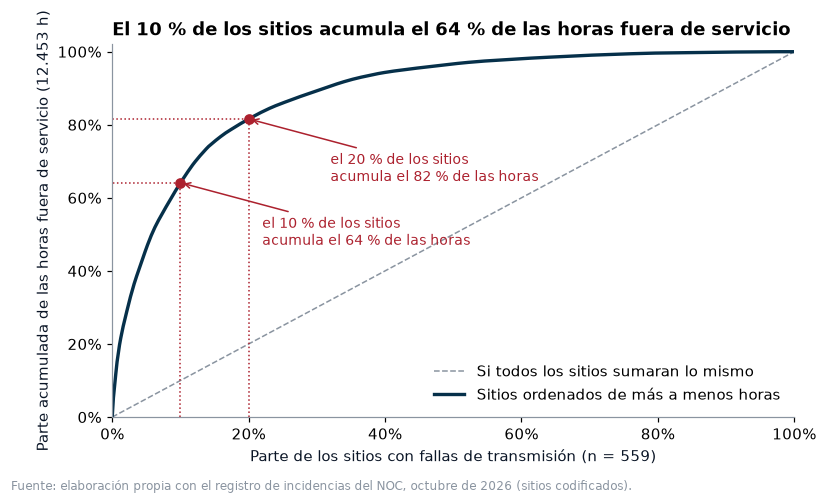

Sitios con fallas de transmisión que afectan el uptime: 559 · horas fuera de servicio: 12.453
Sitios recurrentes (2 o más fallas): 149 (26,7 % de los sitios), con el 44,6 % de las fallas y el 42,2 % de las horas


In [7]:
curva = com.concentracion(recurrencia["horas_fuera"])
total_horas = recurrencia["horas_fuera"].sum()
n_sitios = len(recurrencia)
parte_10, parte_20 = com.parte_del_total(curva, 0.10), com.parte_del_total(curva, 0.20)

recurrentes = recurrencia[recurrencia["fallas"] >= 2]
parte_sitios_rec = len(recurrentes) / n_sitios
parte_horas_rec = recurrentes["horas_fuera"].sum() / total_horas
parte_fallas_rec = recurrentes["fallas"].sum() / recurrencia["fallas"].sum()

figuras = {}
fig, ax = plt.subplots()
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Si todos los sitios sumaran lo mismo")
ax.plot(np.r_[0, curva["parte_elementos"]], np.r_[0, curva["parte_acumulada"]], color=AZUL, lw=2.2,
        label="Sitios ordenados de más a menos horas")
for x, y in [(0.10, parte_10), (0.20, parte_20)]:
    ax.plot([x, x, 0], [0, y, y], color=GRANATE, lw=1, ls=":")
    ax.scatter([x], [y], color=GRANATE, zorder=3)
    ax.annotate(f"el {pct(x)} de los sitios\nacumula el {pct(y)} de las horas", xy=(x, y),
                xytext=(x + 0.12, y - 0.17), color=GRANATE, fontsize=9,
                arrowprops={"arrowstyle": "->", "color": GRANATE})
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel(f"Parte de los sitios con fallas de transmisión (n = {miles(n_sitios)})")
ax.set_ylabel(f"Parte acumulada de las horas fuera de servicio ({miles(total_horas)} h)")
ax.legend(loc="lower right")
ax.set_title(f"El {pct(0.10)} de los sitios acumula el {pct(parte_10)} de las horas fuera de servicio")
nota_fuente(fig)
figuras["fig1_concentracion_horas"] = fig
plt.show()

print(f"Sitios con fallas de transmisión que afectan el uptime: {miles(n_sitios)} · horas fuera de servicio: {miles(total_horas)}")
print(f"Sitios recurrentes (2 o más fallas): {len(recurrentes)} ({pct(parte_sitios_rec, 1)} de los sitios), "
      f"con el {pct(parte_fallas_rec, 1)} de las fallas y el {pct(parte_horas_rec, 1)} de las horas")

**Lectura.** *Qué muestra:* la curva sube muy rápido al comienzo: el 10 % de los 559 sitios acumula el
64 % de las 12.453 horas fuera de servicio por transmisión, y el 20 % acumula el 82 %. Si todos los
sitios sumaran lo mismo, la curva seguiría la diagonal. *Qué se infiere:* el tiempo caído no está
repartido de forma pareja; atender pocos sitios recupera la mayor parte del uptime perdido (objetivos 1
y 2). Los 149 sitios recurrentes (27 % de los sitios) concentran el 45 % de las fallas, pero solo el 42 %
de las horas: hay sitios con **una sola** falla muy larga que también pesan. *Límite:* es un solo mes;
con un mes distinto el orden de los sitios puede cambiar, por lo que la concentración debe confirmarse
con más meses antes de fijar una política.

### Figura 2 · La fibra de proveedor falla más; el satelital, cuando falla, dura más

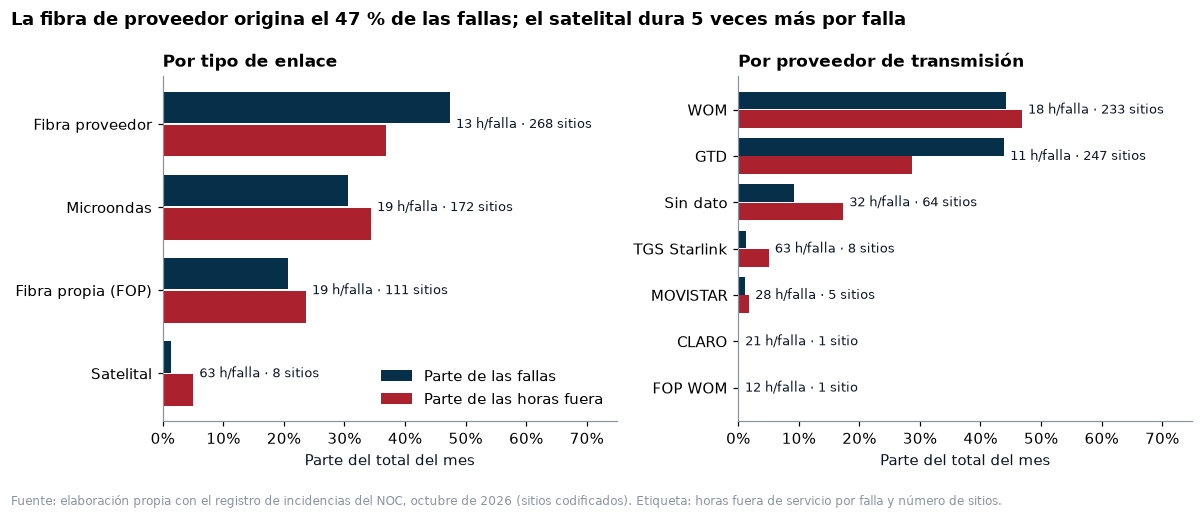

                    sitios  fallas   horas  parte_fallas  parte_horas  horas_por_falla
enlace_principal                                                                      
Fibra proveedor        268     351  4591.8         0.474        0.369           13.082
Microondas             172     226  4284.2         0.305        0.344           18.957
Fibra propia (FOP)     111     153  2947.0         0.207        0.237           19.261
Satelital                8      10   629.9         0.014        0.051           62.990

              sitios  fallas   horas  parte_fallas  parte_horas  horas_por_falla
proveedor_tx                                                                    
WOM              233     327  5836.5         0.442        0.469           17.849
GTD              247     325  3565.9         0.439        0.286           10.972
Sin dato          64      68  2161.0         0.092        0.174           31.779
TGS Starlink       8      10   629.9         0.014        0.051         

In [8]:
por_enlace = com.resumen_por(recurrencia, "enlace_principal").sort_values("parte_fallas")
por_proveedor = com.resumen_por(recurrencia, "proveedor_tx").sort_values("parte_fallas")

fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1]})
for eje, tabla, titulo in [(izq, por_enlace, "Por tipo de enlace"), (der, por_proveedor, "Por proveedor de transmisión")]:
    y = np.arange(len(tabla))
    eje.barh(y + 0.2, tabla["parte_fallas"], height=0.38, color=AZUL, label="Parte de las fallas")
    eje.barh(y - 0.2, tabla["parte_horas"], height=0.38, color=GRANATE, label="Parte de las horas fuera")
    for posicion, (_, fila) in zip(y, tabla.iterrows()):
        eje.text(max(fila["parte_fallas"], fila["parte_horas"]) + 0.01, posicion,
                 f"{fila['horas_por_falla']:.0f} h/falla · {int(fila['sitios'])} sitio{'s' if fila['sitios'] != 1 else ''}",
                 va="center", fontsize=8.5, color=TINTA)
    eje.set_yticks(y, tabla.index)
    eje.xaxis.set_major_formatter(PercentFormatter(1.0))
    eje.set_xlim(0, 0.75)
    eje.set_xlabel("Parte del total del mes")
    eje.set_title(titulo, fontsize=11)
izq.legend(loc="lower right")
satelital = por_enlace.loc["Satelital", "horas_por_falla"]
fibra_prov = por_enlace.loc["Fibra proveedor"]
fig.suptitle(f"La fibra de proveedor origina el {pct(fibra_prov['parte_fallas'])} de las fallas; el satelital dura "
             f"{satelital / fibra_prov['horas_por_falla']:.0f} veces más por falla",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
nota_fuente(fig, FUENTE + " Etiqueta: horas fuera de servicio por falla y número de sitios.")
plt.tight_layout()
figuras["fig2_enlace_y_proveedor"] = fig
plt.show()

columnas = ["sitios", "fallas", "horas", "parte_fallas", "parte_horas", "horas_por_falla"]
print(por_enlace.sort_values("horas", ascending=False)[columnas].round(3).to_string())
print()
print(por_proveedor.sort_values("horas", ascending=False)[columnas].round(3).to_string())

**Lectura.** *Qué muestra:* la fibra de proveedor es el enlace que más falla (47 % de las fallas y 37 %
de las horas), pero cada falla dura en promedio 13 horas. Microondas y fibra propia rondan las 19 horas
por falla. El satelital tiene pocos sitios, pero cada falla dura unas 63 horas. Por proveedor, los
enlaces propios (WOM) suman el 47 % de las horas y GTD casi la misma cantidad de fallas, pero con fallas
más cortas (11 horas). *Qué se infiere:* hay dos problemas distintos que piden respuestas distintas
(objetivo 3). Con el proveedor de fibra conviene escalar la **frecuencia** de las fallas; en microondas
y satelital, el **tiempo de reposición**. *Límite:* 64 sitios no tienen proveedor registrado (17 % de las
horas), por lo que el reparto por proveedor está incompleto. Además, las horas por falla son un promedio
y pueden subir por una sola falla muy larga.

### Figura 3 · Diez sitios encabezan la lista de escalamiento

La lista usa el orden que fijó la Fase 2 para el objetivo 4: primero los sitios con más fallas en el mes
y, a igual número de fallas, los que suman más minutos fuera de servicio. El eje vertical usa escala
logarítmica porque las horas van de menos de una a más de seiscientas; con escala lineal, casi todos los
sitios quedarían pegados al cero.

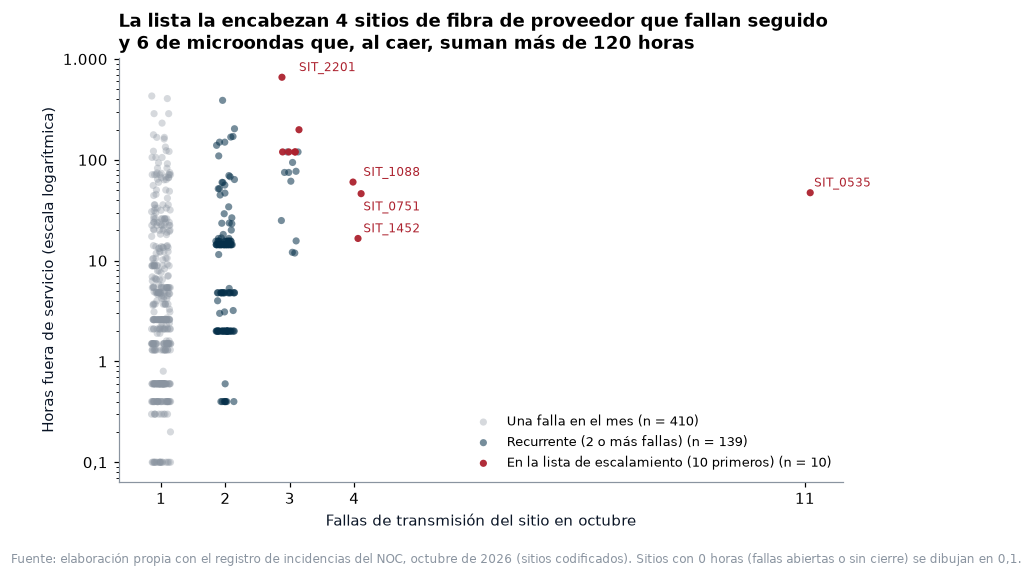

,sitio,fallas,fallas_p3e,horas_fuera,enlace_principal,proveedor_tx,region
0,SIT_0535,11,0,47.2,Fibra proveedor,GTD,X
1,SIT_1088,4,1,60.2,Fibra proveedor,GTD,RM
2,SIT_0751,4,1,46.2,Fibra proveedor,MOVISTAR,VIII
3,SIT_1452,4,0,16.6,Fibra proveedor,GTD,RM
4,SIT_2201,3,3,659.8,Microondas,WOM,IV
5,SIT_1174,3,2,199.0,Microondas,WOM,V
6,SIT_1764,3,2,119.8,Microondas,WOM,VI
7,SIT_1765,3,2,119.8,Microondas,WOM,VI
8,SIT_1766,3,2,119.8,Microondas,WOM,VI
9,SIT_1767,3,2,119.8,Microondas,WOM,VI


In [9]:
prioridad = com.lista_prioridad(recurrencia, n=10)
en_lista = recurrencia["sitio"].isin(prioridad["sitio"])
jitter = rng.uniform(-0.15, 0.15, len(recurrencia))

fig, ax = plt.subplots(figsize=(8.5, 5))
for mascara, color, alfa, etiqueta in [
    ((recurrencia["fallas"] < 2), GRIS, 0.35, "Una falla en el mes"),
    ((recurrencia["fallas"] >= 2) & ~en_lista, AZUL, 0.55, "Recurrente (2 o más fallas)"),
    (en_lista, GRANATE, 0.95, "En la lista de escalamiento (10 primeros)"),
]:
    sub = recurrencia[mascara]
    ax.scatter(sub["fallas"] + jitter[mascara.to_numpy()], sub["horas_fuera"].clip(lower=0.1), s=22,
               color=color, alpha=alfa, edgecolors="none", label=f"{etiqueta} (n = {len(sub)})")
for (_, fila), dy in zip(prioridad.head(5).iterrows(), [4, 4, -11, 4, 4]):   # -11: separa dos etiquetas vecinas
    ax.annotate(fila["sitio"], xy=(fila["fallas"], max(fila["horas_fuera"], 0.1)), xytext=(6, dy),
                textcoords="offset points", fontsize=8, color=GRANATE)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.1f}".rstrip("0").rstrip(".")
                                                             .replace(",", "X").replace(".", ",").replace("X", ".")))
ax.set_xticks(sorted(recurrencia["fallas"].unique()))
ax.set_xlabel("Fallas de transmisión del sitio en octubre")
ax.set_ylabel("Horas fuera de servicio (escala logarítmica)")
ax.legend(loc="lower right", fontsize=8.5)
n_fibra = int((prioridad["enlace_principal"] == "Fibra proveedor").sum())
n_mo = int((prioridad["enlace_principal"] == "Microondas").sum())
ax.set_title(f"La lista la encabezan {n_fibra} sitios de fibra de proveedor que fallan seguido\n"
             f"y {n_mo} de microondas que, al caer, suman más de {prioridad.loc[prioridad['enlace_principal'] == 'Microondas', 'horas_fuera'].min():.0f} horas")
nota_fuente(fig, FUENTE + " Sitios con 0 horas (fallas abiertas o sin cierre) se dibujan en 0,1.")
figuras["fig3_lista_escalamiento"] = fig
plt.show()

prioridad[["sitio", "fallas", "fallas_p3e", "horas_fuera", "enlace_principal", "proveedor_tx", "region"]]

**Lectura.** *Qué muestra:* casi todos los sitios están a la izquierda (una o dos fallas). Los diez
primeros de la lista se separan en dos grupos. Cuatro son de fibra de proveedor, con 4 a 11 fallas en el
mes; el primero, SIT_0535, falló 11 veces. Los otros seis son de microondas, con 3 fallas cada uno y
entre 120 y 660 horas fuera de servicio. *Qué se infiere:* la lista sirve para escalar al área o al
proveedor que corresponde (objetivo 4): los de fibra, al proveedor por recurrencia; los de microondas,
al área de transmisión por tiempo de reposición. *Límite:* seis sitios de microondas (SIT_1764 a
SIT_1769) tienen exactamente las mismas fallas y horas (119,8 h). Eso sugiere que dependen de un mismo
tramo, y en ese caso se trataría de un solo problema y no de seis. La tabla cuenta cada sitio por separado, así que
antes de escalar hay que revisar si comparten un hub o un enlace padre.

---
## 4. Eficiencia: la curva de concentración

La única operación nueva de esta fase es la curva de la figura 1. Se comparan dos formas de calcularla
con `comparar` de `src/medicion.py`, la misma función de la Fase 3: primero comprueba que ambas den el
mismo resultado y después mide el menor tiempo de varias repeticiones (`timeit`) y la memoria máxima
(`tracemalloc`).

- **Ingenua:** para cada k, vuelve a sumar los k mayores desde cero. Hace 1 + 2 + … + n sumas: O(n²).
- **Vectorizada:** ordena una vez y acumula con `np.cumsum`. Cuesta O(n log n) por el orden y O(n) por
  la suma.

Para ver cómo crece cada una no basta un solo tamaño: se mide con los 559 sitios reales y con muestras
más grandes, tomadas con reposición desde las mismas horas y con semilla fija.

In [10]:
horas = recurrencia["horas_fuera"].to_numpy()
mediciones = []
for n in [len(horas), 2_000, 5_000]:
    muestra = horas if n == len(horas) else rng.choice(horas, size=n, replace=True)
    tabla = comparar({"ingenua O(n²)": com.concentracion_ingenua, "vectorizada O(n log n)": com.concentracion},
                     muestra, iguales=lambda a, b: np.allclose(a.to_numpy(), b.to_numpy()), repeticiones=3)
    mediciones.append(tabla.assign(n=n).reset_index())

eficiencia = pd.concat(mediciones, ignore_index=True)
eficiencia["tiempo_ms"] = eficiencia["tiempo_min_s"] * 1000
pivote = eficiencia.pivot(index="n", columns="version", values="tiempo_ms")
pivote["razon"] = pivote["ingenua O(n²)"] / pivote["vectorizada O(n log n)"]
print(eficiencia[["n", "version", "tiempo_ms", "memoria_pico_mb"]].round(3).to_string(index=False))
print()
print(pivote.round(2).to_string())

   n                version  tiempo_ms  memoria_pico_mb
 559          ingenua O(n²)      5.016            0.088
 559 vectorizada O(n log n)      0.227            0.024
2000          ingenua O(n²)     35.288            0.310
2000 vectorizada O(n log n)      0.304            0.079
5000          ingenua O(n²)    202.708            0.778
5000 vectorizada O(n log n)      0.569            0.194

version  ingenua O(n²)  vectorizada O(n log n)   razon
n                                                     
559               5.02                    0.23   22.14
2000             35.29                    0.30  116.19
5000            202.71                    0.57  356.25


**Interpretación.** Las dos versiones entregan la misma curva (`comparar` lo verifica antes de medir).
Con los 559 sitios del mes la diferencia es de milisegundos y daría lo mismo usar cualquiera. Lo que
decide es el crecimiento: cada vez que n se multiplica, el tiempo de la ingenua sube aproximadamente con
el cuadrado y la razón entre ambas crece con n. Con la vectorizada, el informe puede repetirse para un
año completo de incidencias o para todos los sitios de la red sin cambiar el código. Por eso queda la
vectorizada. En memoria, la ingenua además arma listas de Python intermedias, mientras que la
vectorizada trabaja sobre un arreglo de NumPy.

---
## 5. Validación técnica

Tres escenarios, como pide la rúbrica: casos normales, casos límite y excepciones. Cada control queda en
una tabla que se cita en el informe. Después se ejecutan las pruebas automáticas del módulo, que viven en
`tests/test_comunicacion.py` y corren con el mismo comando que las de la Fase 3.

In [11]:
controles = []


def verificar(escenario, control, condicion, detalle=""):
    controles.append({"escenario": escenario, "control": control, "estado": "OK" if condicion else "FALLA",
                      "detalle": detalle})


# Casos normales
verificar("normal", "La curva termina en el 100 % de las horas", np.isclose(curva["parte_acumulada"].iloc[-1], 1.0))
verificar("normal", "Las fallas por enlace suman las fallas de la tabla",
          por_enlace["fallas"].sum() == recurrencia["fallas"].sum(), f"{recurrencia['fallas'].sum()} fallas")
verificar("normal", "La lista de prioridad solo tiene sitios recurrentes", (prioridad["fallas"] >= 2).all())
verificar("normal", "Recalculada desde la tabla limpia = tabla de la Fase 2", recalculo_identico,
          "assert_frame_equal de la sección 2.3")

# Casos límite
verificar("límite", "Sitios con 0 horas se conservan (no se eliminan)", (recurrencia["horas_fuera"] == 0).sum() > 0,
          f"{(recurrencia['horas_fuera'] == 0).sum()} sitios")
verificar("límite", "Curva con un solo sitio", com.concentracion([5.0])["parte_acumulada"].tolist() == [1.0])
verificar("límite", "Valores iguales dan la diagonal",
          np.allclose(com.concentracion([2, 2, 2])["parte_acumulada"], [1 / 3, 2 / 3, 1]))

# Excepciones
for descripcion, llamada, error in [
    ("Faltan las tablas de la Fase 3", lambda: com.cargar_artefactos(RAIZ / "no_existe"), FileNotFoundError),
    ("Curva sin valores", lambda: com.concentracion([]), ValueError),
    ("Resumen por una columna inexistente", lambda: com.resumen_por(recurrencia, "no_existe"), KeyError),
]:
    try:
        llamada()
        verificar("excepción", descripcion, False, "no lanzó error")
    except error:
        verificar("excepción", descripcion, True, error.__name__)

tabla_controles = pd.DataFrame(controles)
assert (tabla_controles["estado"] == "OK").all(), "Hay controles que fallaron"
tabla_controles

,escenario,control,estado,detalle
0,normal,La curva termina en el 100 % de las horas,OK,
1,normal,Las fallas por enlace suman las fallas de la t...,OK,740 fallas
2,normal,La lista de prioridad solo tiene sitios recurr...,OK,
3,normal,Recalculada desde la tabla limpia = tabla de l...,OK,assert_frame_equal de la sección 2.3
4,límite,Sitios con 0 horas se conservan (no se eliminan),OK,17 sitios
5,límite,Curva con un solo sitio,OK,
6,límite,Valores iguales dan la diagonal,OK,
7,excepción,Faltan las tablas de la Fase 3,OK,FileNotFoundError
8,excepción,Curva sin valores,OK,ValueError
9,excepción,Resumen por una columna inexistente,OK,KeyError


In [12]:
cargador = unittest.TestLoader()
suite = cargador.discover(str(RAIZ / "tests"), pattern="test_comunicacion.py")
n_pruebas = suite.countTestCases()
resultado = unittest.TextTestRunner(verbosity=1).run(suite)
print(f"Pruebas del módulo de comunicación: {n_pruebas}, fallidas: {len(resultado.failures) + len(resultado.errors)}")
assert resultado.wasSuccessful()

.................
----------------------------------------------------------------------
Ran 17 tests in 0.083s

OK


Pruebas del módulo de comunicación: 17, fallidas: 0


---
## 6. Lo que se lleva al informe y al video

Las figuras se guardan en `F4/figuras/` a 200 ppp. Los hallazgos, la lista de escalamiento y las
mediciones se guardan en `docs/` con la cifra exacta que los respalda: así el informe y el video se
escriben desde la misma fuente.

In [13]:
rutas = {nombre: com.guardar_figura(figura, DIR_FIG, nombre) for nombre, figura in figuras.items()}

hallazgos = pd.DataFrame([
    {"figura": "fig1_concentracion_horas", "objetivo": "1 y 2",
     "hallazgo": "Pocos sitios concentran la mayor parte del tiempo fuera de servicio",
     "evidencia": f"El 10 % de los sitios acumula el {pct(parte_10)} de las horas y el 20 % el {pct(parte_20)}; "
                  f"los {len(recurrentes)} recurrentes suman el {pct(parte_horas_rec)} de las horas"},
    {"figura": "fig2_enlace_y_proveedor", "objetivo": "3",
     "hallazgo": "La fibra de proveedor falla más; microondas y satelital duran más por falla",
     "evidencia": f"Fibra de proveedor: {pct(fibra_prov['parte_fallas'])} de las fallas y "
                  f"{fibra_prov['horas_por_falla']:.0f} h/falla; satelital: {satelital:.0f} h/falla"},
    {"figura": "fig3_lista_escalamiento", "objetivo": "4",
     "hallazgo": "Diez sitios encabezan la lista de escalamiento",
     "evidencia": f"{n_fibra} de fibra de proveedor por recurrencia y {n_mo} de microondas por tiempo fuera"},
])
hallazgos.to_csv(DIR_DOCS / "hallazgos_f4.csv", index=False)
prioridad.to_csv(DIR_DOCS / "prioridad_escalamiento_f4.csv", index=False)
eficiencia[["n", "version", "tiempo_ms", "memoria_pico_mb"]].round(4).to_csv(DIR_DOCS / "mediciones_eficiencia_f4.csv", index=False)

metadatos = {
    "fase": "F4",
    "fecha_ejecucion": date.today().isoformat(),
    "commit": git("rev-parse", "--short", "HEAD"),
    "semilla": SEMILLA,
    "python": platform.python_version(),
    "dependencias": {"numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
    "entradas": [f"data/processed/{archivo}" for archivo in com.ARTEFACTOS.values()],
    "recurrencia_identica_al_recalculo": True,
    "figuras": [ruta.relative_to(RAIZ).as_posix() for ruta in rutas.values()],
    "controles_superados": int((tabla_controles["estado"] == "OK").sum()),
    "pruebas_modulo": n_pruebas,
    "cifras": {"sitios": n_sitios, "horas_fuera": round(float(total_horas), 1), "sitios_recurrentes": len(recurrentes),
               "parte_horas_10pct_sitios": round(parte_10, 4), "parte_horas_20pct_sitios": round(parte_20, 4)},
}
(DIR_DOCS / "metadatos_fase4.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")

for nombre, ruta in rutas.items():
    print(f"{nombre:<26} {ruta.relative_to(RAIZ).as_posix()}  ({ruta.stat().st_size / 1024:.0f} KB)")
for archivo in ["hallazgos_f4.csv", "prioridad_escalamiento_f4.csv", "mediciones_eficiencia_f4.csv", "metadatos_fase4.json"]:
    print("docs/" + archivo)
hallazgos

fig1_concentracion_horas   F4/figuras/fig1_concentracion_horas.png  (141 KB)
fig2_enlace_y_proveedor    F4/figuras/fig2_enlace_y_proveedor.png  (153 KB)
fig3_lista_escalamiento    F4/figuras/fig3_lista_escalamiento.png  (153 KB)
docs/hallazgos_f4.csv
docs/prioridad_escalamiento_f4.csv
docs/mediciones_eficiencia_f4.csv
docs/metadatos_fase4.json


,figura,objetivo,hallazgo,evidencia
0,fig1_concentracion_horas,1 y 2,Pocos sitios concentran la mayor parte del tie...,El 10 % de los sitios acumula el 64 % de las h...
1,fig2_enlace_y_proveedor,3,La fibra de proveedor falla más; microondas y ...,Fibra de proveedor: 47 % de las fallas y 13 h/...
2,fig3_lista_escalamiento,4,Diez sitios encabezan la lista de escalamiento,4 de fibra de proveedor por recurrencia y 6 de...


---
## 7. El relato en tres actos

El informe y el video cuentan lo mismo, en este orden:

**Acto 1 · El problema.** En octubre de 2026, 559 sitios tuvieron fallas de transmisión que afectaron el
uptime y sumaron 12.453 horas fuera de servicio. La pregunta es dónde se concentra ese tiempo
(figura 1).

**Acto 2 · Lo que muestran los datos.** El tiempo caído está muy concentrado: el 10 % de los sitios
acumula casi dos tercios de las horas. La fibra de proveedor es la que más falla y la microondas y el
satelital los que más tardan en volver (figura 2).

**Acto 3 · Qué hacer y qué no se puede afirmar.** Diez sitios encabezan la lista de escalamiento, en dos
grupos con dos respuestas distintas (figura 3). Es un solo mes y los sitios en cadena se cuentan por
separado, así que la lista orienta el escalamiento pero no reemplaza la revisión técnica de cada caso.

### Limitaciones que el informe debe declarar

1. Es un solo mes de datos: la concentración y el orden de los sitios deben confirmarse con más meses.
2. 64 sitios no tienen proveedor de transmisión registrado (17 % de las horas).
3. Los sitios que dependen de un mismo tramo se cuentan por separado y pueden inflar la recurrencia.
4. Las fallas abiertas al cierre del mes cuentan como falla pero no suman horas.
5. Las horas por falla son promedios y una sola falla muy larga puede moverlos.